<a href="https://colab.research.google.com/github/Saksham-Xtreme/Machine_Learning_Study/blob/main/Smart_Irrigation_Requirement_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Smart Irrigation Requirement Prediction using Machine Learning
# Step 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [6]:

from google.colab import files

uploaded = files.upload()


Saving train.csv to train.csv


In [7]:

import pandas as pd

train = pd.read_csv("train.csv")

print("Dataset shape:", train.shape)
print("\nColumns:", train.columns.tolist())
display(train.head())


Dataset shape: (630000, 21)

Columns: ['id', 'Soil_Type', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity', 'Temperature_C', 'Humidity', 'Rainfall_mm', 'Sunlight_Hours', 'Wind_Speed_kmh', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Water_Source', 'Field_Area_hectare', 'Mulching_Used', 'Previous_Irrigation_mm', 'Region', 'Irrigation_Need']


,id,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,...,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,0,Loamy,4.92,32.58,1.01,3.05,15.01,50.61,725.99,5.90,...,Sugarcane,Sowing,Zaid,Drip,Rainwater,0.82,No,112.16,East,Low
1,1,Clay,7.08,56.61,0.44,2.00,22.92,67.86,985.66,6.98,...,Wheat,Vegetative,Kharif,Rainfed,River,5.27,Yes,47.16,South,Low
2,2,Clay,5.69,27.71,0.81,2.83,26.97,92.22,2201.70,6.05,...,Rice,Vegetative,Kharif,Sprinkler,Reservoir,8.24,Yes,110.38,North,Low
3,3,Sandy,5.65,13.32,1.33,0.87,13.32,61.57,1357.33,9.12,...,Wheat,Flowering,Kharif,Canal,River,8.32,Yes,53.85,South,Medium
4,4,Clay,7.96,59.14,0.38,0.96,20.22,91.11,1538.20,6.95,...,Wheat,Sowing,Rabi,Canal,River,7.37,No,93.19,South,Low


Numerical columns: ['id', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity', 'Temperature_C', 'Humidity', 'Rainfall_mm', 'Sunlight_Hours', 'Wind_Speed_kmh', 'Field_Area_hectare', 'Previous_Irrigation_mm']

Categorical columns: ['Soil_Type', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Water_Source', 'Mulching_Used', 'Region', 'Irrigation_Need']


,count,mean,std,min,25%,50%,75%,max
id,630000.0,314999.500000,181865.479132,0.00,157499.7500,314999.50,472499.25,629999.00
Soil_pH,630000.0,6.482497,0.922504,4.80,5.6900,6.44,7.27,8.20
Soil_Moisture,630000.0,37.304482,16.377082,8.00,23.3400,37.75,51.27,64.99
Organic_Carbon,630000.0,0.922858,0.365808,0.30,0.6100,0.91,1.22,1.60
Electrical_Conductivity,630000.0,1.744605,0.952321,0.10,0.9300,1.74,2.58,3.50
Temperature_C,630000.0,26.998166,8.623621,12.00,19.5175,26.96,34.54,42.00
Humidity,630000.0,61.563180,19.708152,25.00,45.3900,61.65,79.12,94.99
Rainfall_mm,630000.0,1462.207566,612.989738,0.38,954.5700,1467.16,2054.28,2499.69
Sunlight_Hours,630000.0,7.513382,1.999322,4.00,5.7600,7.58,9.25,11.00
Wind_Speed_kmh,630000.0,10.375394,5.689458,0.50,5.2800,10.48,15.43,20.00


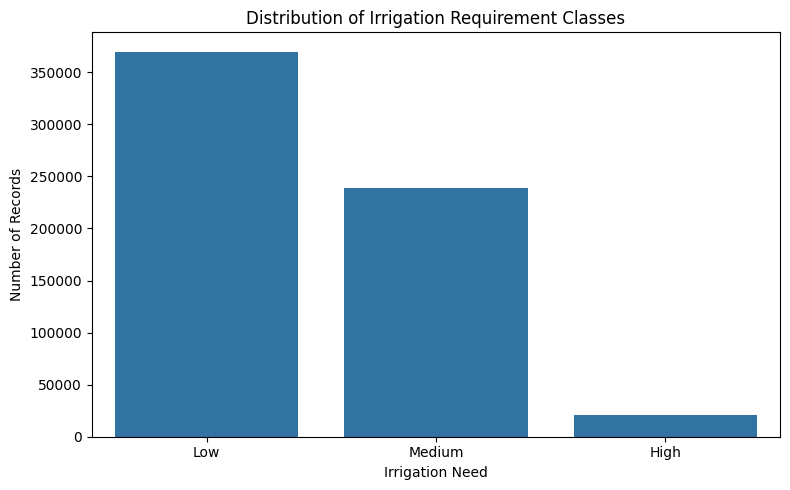

In [8]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Separate numerical and categorical columns
numerical_cols = train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)

# Numerical statistics
display(train[numerical_cols].describe().T)

# Class distribution plot
plt.figure(figsize=(8, 5))
sns.countplot(
    data=train,
    x="Irrigation_Need",
    order=["Low", "Medium", "High"]
)
plt.title("Distribution of Irrigation Requirement Classes")
plt.xlabel("Irrigation Need")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


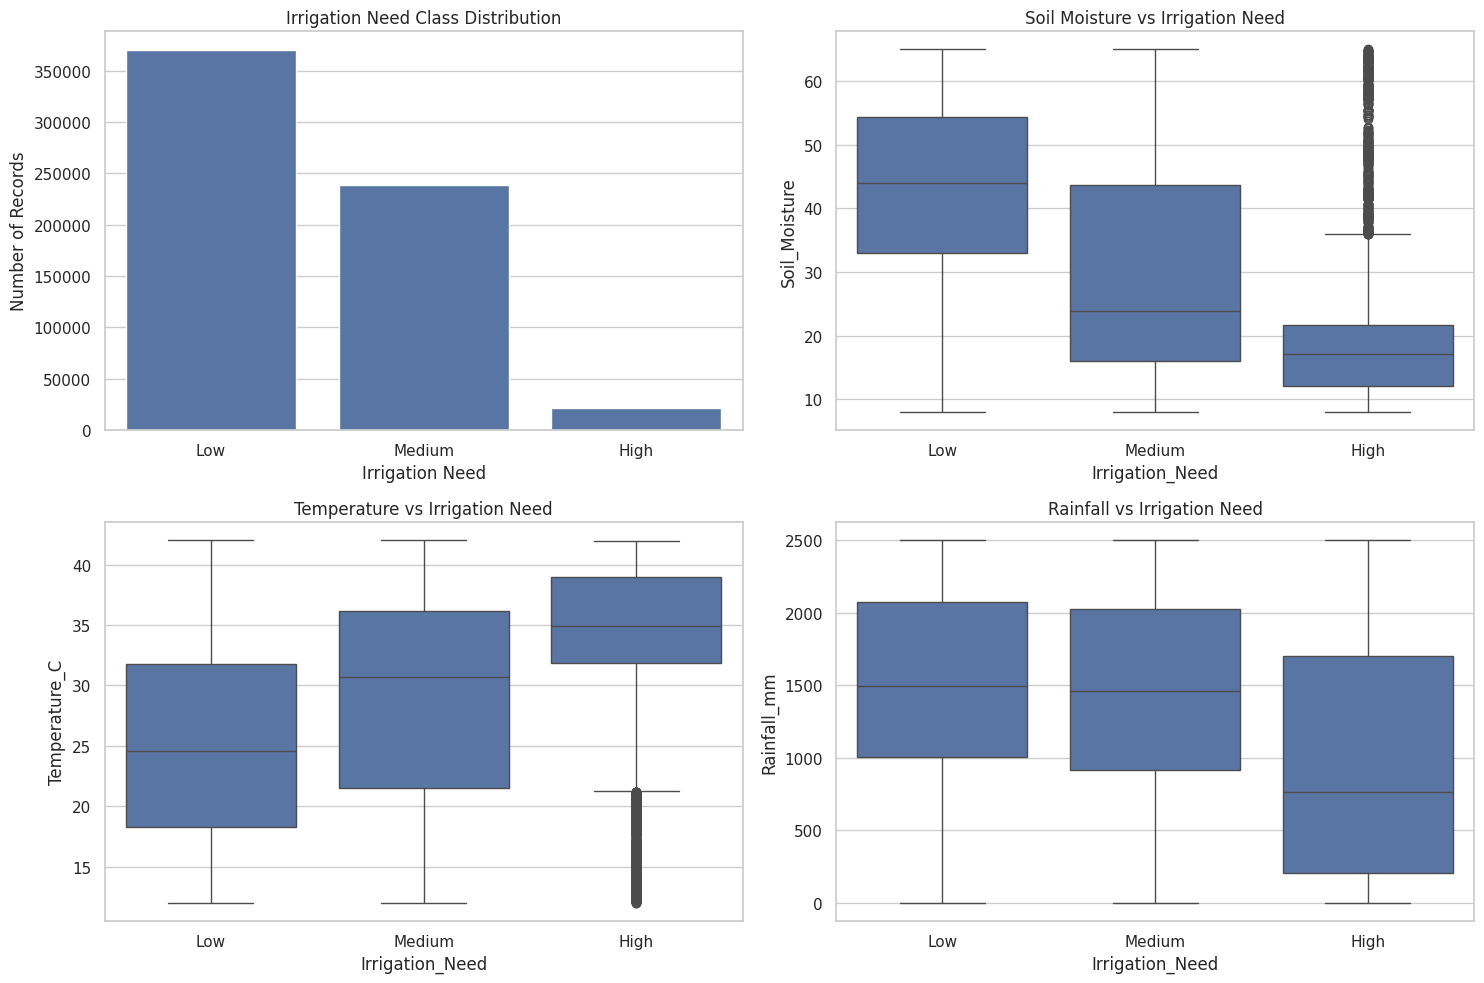

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Target class distribution
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.countplot(
    data=train,
    x="Irrigation_Need",
    order=["Low", "Medium", "High"],
    ax=axes[0, 0]
)
axes[0, 0].set_title("Irrigation Need Class Distribution")
axes[0, 0].set_xlabel("Irrigation Need")
axes[0, 0].set_ylabel("Number of Records")

# 2. Soil moisture by irrigation need
sns.boxplot(
    data=train,
    x="Irrigation_Need",
    y="Soil_Moisture",
    order=["Low", "Medium", "High"],
    ax=axes[0, 1]
)
axes[0, 1].set_title("Soil Moisture vs Irrigation Need")

# 3. Temperature by irrigation need
sns.boxplot(
    data=train,
    x="Irrigation_Need",
    y="Temperature_C",
    order=["Low", "Medium", "High"],
    ax=axes[1, 0]
)
axes[1, 0].set_title("Temperature vs Irrigation Need")

# 4. Rainfall by irrigation need
sns.boxplot(
    data=train,
    x="Irrigation_Need",
    y="Rainfall_mm",
    order=["Low", "Medium", "High"],
    ax=axes[1, 1]
)
axes[1, 1].set_title("Rainfall vs Irrigation Need")

plt.tight_layout()
plt.show()


In [10]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = train.drop(columns=["Irrigation_Need", "id"])
y = train["Irrigation_Need"]

# Identify feature types
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nFeature count:", X.shape[1])

# Stratified 80:20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(4))


Numerical features: ['Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity', 'Temperature_C', 'Humidity', 'Rainfall_mm', 'Sunlight_Hours', 'Wind_Speed_kmh', 'Field_Area_hectare', 'Previous_Irrigation_mm']

Categorical features: ['Soil_Type', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Water_Source', 'Mulching_Used', 'Region']

Feature count: 19

Training set: (504000, 19)
Testing set: (126000, 19)

Training class proportions:
Irrigation_Need
Low       0.5872
Medium    0.3795
High      0.0333
Name: proportion, dtype: float64

Testing class proportions:
Irrigation_Need
Low       0.5872
Medium    0.3795
High      0.0333
Name: proportion, dtype: float64


Training Logistic Regression...
Training time: 8.60 seconds

Accuracy:          0.8420
Balanced Accuracy: 0.8505
Macro F1-score:    0.7432
Weighted F1-score: 0.8497

Classification Report:
              precision    recall  f1-score   support

         Low       0.93      0.88      0.91     73983
      Medium       0.80      0.78      0.79     47815
        High       0.38      0.89      0.53      4202

    accuracy                           0.84    126000
   macro avg       0.71      0.85      0.74    126000
weighted avg       0.87      0.84      0.85    126000



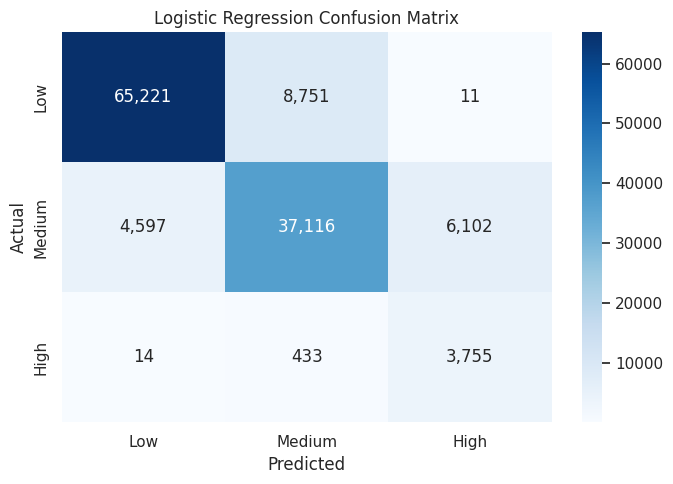

In [11]:

import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Identify feature types
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Logistic Regression baseline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train
print("Training Logistic Regression...")
start = time.time()
baseline_model.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.2f} seconds")

# Predict
y_pred = baseline_model.predict(X_test)

# Evaluate
print(f"\nAccuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1-score:    {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Weighted F1-score: {f1_score(y_test, y_pred, average='weighted'):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


Training Random Forest...
Training time: 97.84 seconds

===== RANDOM FOREST RESULTS =====
Accuracy:          0.9857
Balanced Accuracy: 0.9667
Macro F1-score:    0.9707
Weighted F1-score: 0.9856

Classification Report:
              precision    recall  f1-score   support

         Low       0.99      1.00      0.99     73983
      Medium       0.99      0.98      0.98     47815
        High       0.95      0.93      0.94      4202

    accuracy                           0.99    126000
   macro avg       0.97      0.97      0.97    126000
weighted avg       0.99      0.99      0.99    126000



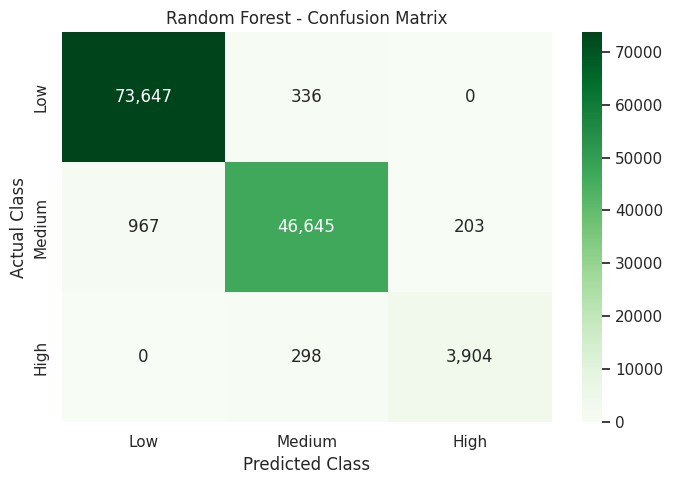


===== MODEL COMPARISON =====


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Logistic Regression,0.8420,0.8505,0.7432,0.8497
1,Random Forest,0.9857,0.9667,0.9707,0.9856


In [12]:

# ============================================================
# MODEL 2: RANDOM FOREST CLASSIFIER
# ============================================================

import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Preprocessing
numeric_transformer_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_rf = ColumnTransformer([
    ("num", numeric_transformer_rf, numeric_features),
    ("cat", categorical_transformer_rf, categorical_features)
])

# 2. Create model
rf_model = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# 3. Train
print("Training Random Forest...")
start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time
print(f"Training time: {rf_training_time:.2f} seconds")

# 4. Predict
rf_pred = rf_model.predict(X_test)

# 5. Evaluate
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_balanced_accuracy = balanced_accuracy_score(y_test, rf_pred)
rf_macro_f1 = f1_score(y_test, rf_pred, average="macro")
rf_weighted_f1 = f1_score(y_test, rf_pred, average="weighted")

print("\n===== RANDOM FOREST RESULTS =====")
print(f"Accuracy:          {rf_accuracy:.4f}")
print(f"Balanced Accuracy: {rf_balanced_accuracy:.4f}")
print(f"Macro F1-score:    {rf_macro_f1:.4f}")
print(f"Weighted F1-score: {rf_weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

# 6. Confusion matrix
cm_rf = confusion_matrix(
    y_test,
    rf_pred,
    labels=["Low", "Medium", "High"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt=",",
    cmap="Greens",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# 7. Compare against Logistic Regression
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        rf_accuracy
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_test, y_pred),
        rf_balanced_accuracy
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro"),
        rf_macro_f1
    ],
    "Weighted F1": [
        f1_score(y_test, y_pred, average="weighted"),
        rf_weighted_f1
    ]
})

print("\n===== MODEL COMPARISON =====")
display(comparison.round(4))
